In [ ]:
from google.colab import files
uploaded = files.upload()

Saving dhaka_aqi_master_2016_2022.csv to dhaka_aqi_master_2016_2022.csv


In [ ]:
import pandas as pd
df = pd.read_csv("dhaka_aqi_master_2016_2022.csv")
print(df.shape)
df.head()

(56233, 14)


,datetime,year,month,day_of_week,hour,is_weekend,season,pm25_raw,pm25_nowcast,aqi,aqi_category,pm25_lag_1h,pm25_lag_24h,was_missing
0,2016-01-01 01:00:00,2016,1,4,1,1,Winter,NaN,NaN,NaN,NaN,NaN,NaN,True
1,2016-01-01 02:00:00,2016,1,4,2,1,Winter,NaN,NaN,NaN,NaN,NaN,NaN,True
2,2016-01-01 03:00:00,2016,1,4,3,1,Winter,NaN,NaN,NaN,NaN,NaN,NaN,True
3,2016-01-01 04:00:00,2016,1,4,4,1,Winter,NaN,NaN,NaN,NaN,NaN,NaN,True
4,2016-01-01 05:00:00,2016,1,4,5,1,Winter,NaN,NaN,NaN,NaN,NaN,NaN,True


In [ ]:

# Check how much data is actually missing/valid overall
print("Total rows:", len(df))
print("Missing pm25_raw:", df['pm25_raw'].isna().sum())
print("Valid pm25_raw:", df['pm25_raw'].notna().sum())

# Check where real data starts
print("\nFirst valid PM2.5 reading:")
print(df[df['pm25_raw'].notna()].iloc[0])

Total rows: 56233
Missing pm25_raw: 2454
Valid pm25_raw: 53779

First valid PM2.5 reading:
datetime        2016-02-29 02:00:00
year                           2016
month                             2
day_of_week                       0
hour                              2
is_weekend                        0
season                       Winter
pm25_raw                      196.0
pm25_nowcast                    NaN
aqi                             NaN
aqi_category                    NaN
pm25_lag_1h                     NaN
pm25_lag_24h                    NaN
was_missing                    True
Name: 1417, dtype: object


In [ ]:
# Drop rows with missing target or lag features (can't train on NaN)
model_df = df.dropna(subset=["pm25_raw", "pm25_lag_1h", "pm25_lag_24h", "aqi"]).copy()
print("Original shape:", df.shape)
print("After dropping remaining NaNs:", model_df.shape)

# Features & target
feature_cols = ["month", "day_of_week", "hour", "is_weekend", "pm25_lag_1h", "pm25_lag_24h"]
X = model_df[feature_cols]
y = model_df["pm25_raw"]

# Convert datetime column properly (Colab loaded it as string, needs to be datetime type)
model_df["datetime"] = pd.to_datetime(model_df["datetime"])

# Chronological split (train on 2016-2021, test on 2022)
split_date = "2022-01-01"
train_mask = model_df["datetime"] < split_date
X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]

print(f"\nTrain size: {len(X_train)} | Test size: {len(X_test)}")


Original shape: (56233, 14)
After dropping remaining NaNs: (52262, 14)

Train size: 48692 | Test size: 3570


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Scale features (important for Neural Network convergence later)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

results = {}

# Linear Regression
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
pred_lr = lr.predict(X_test_scaled)
results["Linear Regression"] = pred_lr

# Random Forest (doesn't need scaling)
rf = RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
results["Random Forest"] = pred_rf

print("Models trained successfully!")
print("Linear Regression sample predictions:", pred_lr[:5])
print("Random Forest sample predictions:", pred_rf[:5])

Models trained successfully!
Linear Regression sample predictions: [132.59016487 129.87893412 129.83967444 122.87565711 119.03450849]
Random Forest sample predictions: [140.38704957 139.34527116 137.9145184  134.42611558 123.50216532]


In [ ]:
from sklearn.neural_network import MLPRegressor

mlp = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    max_iter=500,
    early_stopping=True,
    random_state=42
)
mlp.fit(X_train_scaled, y_train)
pred_mlp = mlp.predict(X_test_scaled)
results["Neural Network (MLP)"] = pred_mlp

print("Neural Network trained successfully!")
print("Sample predictions:", pred_mlp[:5])

Neural Network trained successfully!
Sample predictions: [140.90964476 136.08272971 139.67637887 132.75714963 127.69081563]


In [ ]:
comparison = []
for name, pred in results.items():
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    comparison.append({"Model": name, "RMSE": round(rmse, 2), "MAE": round(mae, 2), "R2": round(r2, 4)})

import pandas as pd
comparison_df = pd.DataFrame(comparison).sort_values("RMSE")
print("=== Model Comparison (on 2022 unseen test data) ===")
print(comparison_df.to_string(index=False))

=== Model Comparison (on 2022 unseen test data) ===
               Model  RMSE   MAE     R2
Neural Network (MLP) 30.22 17.92 0.8239
       Random Forest 31.21 18.50 0.8123
   Linear Regression 31.59 19.20 0.8077


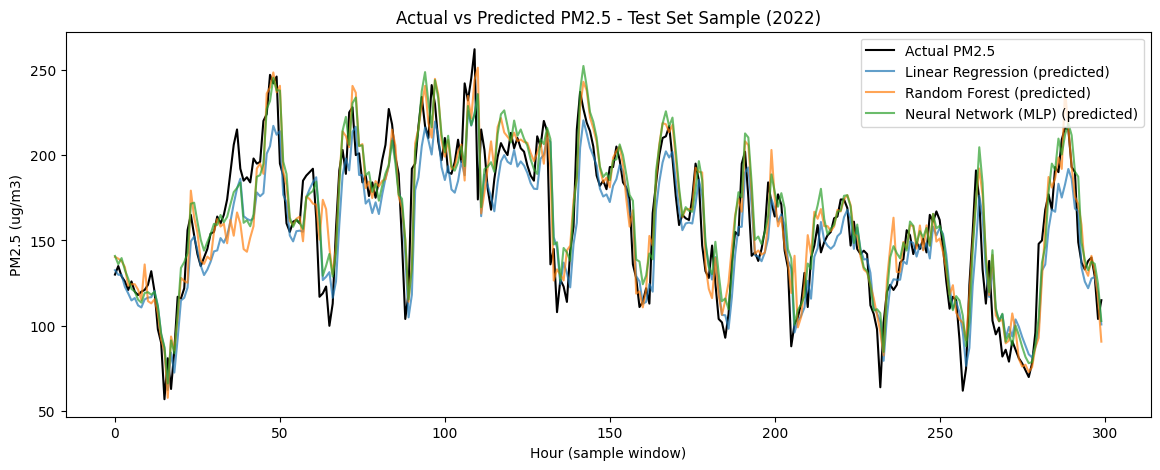

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
sample = slice(0, 300)  # first ~300 hours of test set for clarity
plt.plot(y_test.values[sample], label="Actual PM2.5", color="black", linewidth=1.5)
for name, pred in results.items():
    plt.plot(pred[sample], label=f"{name} (predicted)", alpha=0.7)
plt.title("Actual vs Predicted PM2.5 - Test Set Sample (2022)")
plt.xlabel("Hour (sample window)")
plt.ylabel("PM2.5 (ug/m3)")
plt.legend()
plt.show()

In [ ]:
from sklearn.cluster import KMeans

# Cluster hours based on pollution + time pattern
cluster_features = model_df[["pm25_raw", "aqi", "hour", "month"]].copy()
cluster_scaled = StandardScaler().fit_transform(cluster_features)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
model_df["cluster"] = kmeans.fit_predict(cluster_scaled)

cluster_summary = model_df.groupby("cluster")[["pm25_raw", "aqi"]].mean().round(1)
cluster_summary["count"] = model_df.groupby("cluster").size()
print("=== K-means Cluster Summary (4 clusters) ===")
print(cluster_summary)

=== K-means Cluster Summary (4 clusters) ===
         pm25_raw    aqi  count
cluster                        
0           204.9  246.7   9096
1            49.6  119.9  18429
2           137.5  201.4   8875
3            41.8  110.6  15862


PC1 explains 47.6% variance
PC2 explains 14.3% variance
Total explained: 61.9%


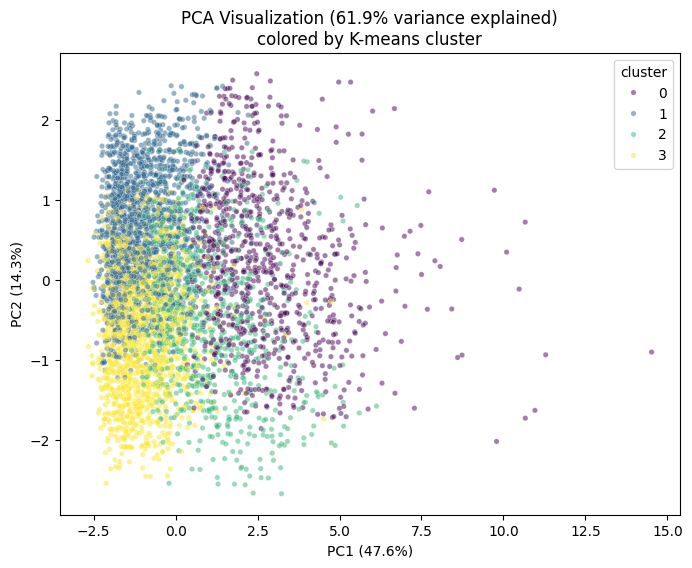

In [ ]:
from sklearn.decomposition import PCA
import seaborn as sns

pca_features = model_df[["pm25_raw", "aqi", "hour", "month", "day_of_week", "pm25_lag_1h", "pm25_lag_24h"]]
pca_scaled = StandardScaler().fit_transform(pca_features)

pca = PCA(n_components=2)
pca_result = pca.fit_transform(pca_scaled)
model_df["pca1"] = pca_result[:, 0]
model_df["pca2"] = pca_result[:, 1]

explained_var = pca.explained_variance_ratio_
print(f"PC1 explains {explained_var[0]*100:.1f}% variance")
print(f"PC2 explains {explained_var[1]*100:.1f}% variance")
print(f"Total explained: {sum(explained_var)*100:.1f}%")

# Plot PCA colored by cluster
plt.figure(figsize=(8, 6))
sample_df = model_df.sample(n=min(5000, len(model_df)), random_state=42)
sns.scatterplot(data=sample_df, x="pca1", y="pca2", hue="cluster", palette="viridis", alpha=0.5, s=15)
plt.title(f"PCA Visualization ({sum(explained_var)*100:.1f}% variance explained)\ncolored by K-means cluster")
plt.xlabel(f"PC1 ({explained_var[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({explained_var[1]*100:.1f}%)")
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

# LSTM needs SEQUENCES (e.g., past 24 hours) to predict the next value
# Let's build sequences from pm25_raw

def create_sequences(data, seq_length=24):
    X_seq, y_seq = [], []
    for i in range(len(data) - seq_length):
        X_seq.append(data[i:i+seq_length])
        y_seq.append(data[i+seq_length])
    return np.array(X_seq), np.array(y_seq)

# Use only pm25_raw values, sorted chronologically (already sorted)
pm25_values = model_df["pm25_raw"].values

# Scale to 0-1 range (LSTM trains better with normalized data)
from sklearn.preprocessing import MinMaxScaler
lstm_scaler = MinMaxScaler()
pm25_scaled = lstm_scaler.fit_transform(pm25_values.reshape(-1, 1))

SEQ_LENGTH = 24  # use past 24 hours to predict next hour
X_lstm, y_lstm = create_sequences(pm25_scaled, SEQ_LENGTH)
print("Sequence shape:", X_lstm.shape, "Target shape:", y_lstm.shape)

TensorFlow version: 2.20.0
Sequence shape: (52238, 24, 1) Target shape: (52238, 1)


In [ ]:
# Chronological split (same logic as before - last ~3570 samples ~ 2022 data)
split_idx = len(X_lstm) - 3570  # keep test set roughly same size as before

X_train_lstm, X_test_lstm = X_lstm[:split_idx], X_lstm[split_idx:]
y_train_lstm, y_test_lstm = y_lstm[:split_idx], y_lstm[split_idx:]

print("Train shape:", X_train_lstm.shape, "Test shape:", X_test_lstm.shape)

# Build LSTM model
model_lstm = keras.Sequential([
    layers.LSTM(50, activation="relu", input_shape=(SEQ_LENGTH, 1)),
    layers.Dense(1)
])

model_lstm.compile(optimizer="adam", loss="mse")
model_lstm.summary()

Train shape: (48668, 24, 1) Test shape: (3570, 24, 1)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model_lstm.fit(
    X_train_lstm, y_train_lstm,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
1369/1369 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - loss: 0.0025 - val_loss: 5.6268e-04
Epoch 2/20
1369/1369 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - loss: 0.0019 - val_loss: 5.4968e-04
Epoch 3/20
1369/1369 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - loss: 0.0019 - val_loss: 5.5831e-04
Epoch 4/20
1369/1369 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - loss: 0.0018 - val_loss: 5.1664e-04
Epoch 5/20
1369/1369 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - loss: 0.0018 - val_loss: 5.4053e-04
Epoch 6/20
1369/1369 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - loss: 0.0018 - val_loss: 5.1803e-04
Epoch 7/20
1369/1369 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - loss: 0.0018 - val_loss: 5.0366e-04
Epoch 8/20
1369/1369 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - loss: 0.0018 - val_loss: 5.0448e-04
Epoch 9/20
1369/1369 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - loss: 0.0018 - val_loss: 5.6029e-04
Epoch 10/20
1369/1369 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - loss: 0.0018 - val_loss: 5.0671e-04
Epoch 11/20
1369/1369 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - 

In [ ]:
# Predict on test set
pred_lstm_scaled = model_lstm.predict(X_test_lstm)

# Inverse transform back to original PM2.5 scale (since we scaled 0-1 earlier)
pred_lstm = lstm_scaler.inverse_transform(pred_lstm_scaled)
y_test_lstm_original = lstm_scaler.inverse_transform(y_test_lstm)

# Calculate metrics
rmse_lstm = np.sqrt(mean_squared_error(y_test_lstm_original, pred_lstm))
mae_lstm = mean_absolute_error(y_test_lstm_original, pred_lstm)
r2_lstm = r2_score(y_test_lstm_original, pred_lstm)

print(f"LSTM RMSE: {rmse_lstm:.2f}")
print(f"LSTM MAE: {mae_lstm:.2f}")
print(f"LSTM R2: {r2_lstm:.4f}")

# Add to comparison table
lstm_row = pd.DataFrame([{"Model": "LSTM (Deep Learning)", "RMSE": round(rmse_lstm,2), "MAE": round(mae_lstm,2), "R2": round(r2_lstm,4)}])
final_comparison = pd.concat([comparison_df, lstm_row], ignore_index=True).sort_values("RMSE")
print("\n=== FINAL Model Comparison (all 4 models) ===")
print(final_comparison.to_string(index=False))

112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
LSTM RMSE: 30.35
LSTM MAE: 17.80
LSTM R2: 0.8225

=== FINAL Model Comparison (all 4 models) ===
               Model  RMSE   MAE     R2
Neural Network (MLP) 30.22 17.92 0.8239
LSTM (Deep Learning) 30.35 17.80 0.8225
       Random Forest 31.21 18.50 0.8123
   Linear Regression 31.59 19.20 0.8077


In [ ]:
import json

# Average PM2.5, AQI by month and hour (from your cleaned dataset)
monthly_hourly = model_df.groupby(["month", "hour"])[["pm25_raw", "aqi"]].mean().round(1).reset_index()

# Average cluster info by month/hour (most common cluster in that time slot)
cluster_mode = model_df.groupby(["month", "hour"])["cluster"].agg(lambda x: x.value_counts().index[0]).reset_index()
monthly_hourly = monthly_hourly.merge(cluster_mode, on=["month", "hour"])

# Convert to a list of dicts for easy JS use
demo_data = monthly_hourly.to_dict(orient="records")

# Save as JSON
with open("demo_data.json", "w") as f:
    json.dump(demo_data, f)

print("Sample of data:")
print(monthly_hourly.head(10))
print(f"\nTotal combinations: {len(demo_data)}")

# Download the file
from google.colab import files
files.download("demo_data.json")

Sample of data:
   month  hour  pm25_raw    aqi  cluster
0      1     0     234.3  278.8        0
1      1     1     228.8  279.1        0
2      1     2     225.1  277.3        0
3      1     3     217.5  272.9        0
4      1     4     214.0  269.2        0
5      1     5     206.9  264.7        0
6      1     6     210.0  263.7        0
7      1     7     212.5  264.0        0
8      1     8     218.4  265.5        0
9      1     9     215.5  265.3        0

Total combinations: 288


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>